# ¿Qué método lo hace mejor y bajo qué protocolo? Los métodos de la referencia comparativa sobre un mismo protocolo

**Pregunta:** Dos números de dos protocolos no ordenan dos métodos, así que ¿cómo pone el producto los métodos que corre sobre un solo protocolo por pregunta, cómo decide cada métrica cuál método es el mejor y qué no dice nunca esa clasificación sobre un método, uno propuesto incluido?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** notebooks 01 a 06 de este tema
- **Tiempo de lectura:** unos 80 minutos

## Objetivos

Al terminar este notebook puedes:

- abrir el documento `data/derived/benchmark/methods-compared.json` y decir qué guardan una pregunta, una corrida, una métrica, una fila y una celda, y por qué cada valor lleva una ruta, un puntero y una huella;
- mostrar con los números del propio documento por qué dos protocolos no pueden mezclarse en una sola clasificación;
- escribir como ecuaciones las cinco reglas que puede declarar una métrica (menor, mayor, más cerca de un valor, más cerca de otra métrica, un orden de categorías), con los empates conservados y un nulo nunca clasificado;
- mostrar por simulación por qué un valor p es contexto y nunca una puntuación;
- recalcular las clasificaciones de las doce preguntas desde sus celdas con las reglas declaradas y ver que coinciden con las del propio documento;
- seguir un valor citado hasta su archivo de origen, resolver su puntero JSON como lo hace el constructor y comparar su huella;
- contar con qué frecuencia un método propuesto en este trabajo es el mejor y con cuál no lo es, y nombrar cada resultado negativo con el manuscrito que lo informa;
- leer el estado de verdad de cada corrida y las celdas nulas con sus razones, decir dónde falla la comparación y colocar un método propio junto a las filas de una pregunta sin presentar un número como comparable cuando su protocolo difiere.

## Preparación

Instala el entorno fijado una sola vez, en un entorno virtual, con el comando conocido:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 pandas==3.0.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El documento lo construye un paso de la cadena de cálculo del producto, `pipeline.benchmark.methods`, y el notebook importa ese módulo por sus lectores (`pointer_get`, `sha256_of`), por la función que elige la mejor fila de una columna (`best_of`) y por la que construye las clasificaciones (`standings_of`): una sola regla para el constructor, las pruebas y este notebook, nunca una copia. La cadena de cálculo son scripts sueltos y no un paquete, así que la celda siguiente pone primero `data-pipeline/` en la ruta de importación. El motor `riskvalidation` aporta las pruebas que corre el notebook (Kupiec, la zona de Basilea, el AUC, la puntuación de Brier y el error de calibración, la prueba de Spiegelhalter). El notebook lee solo archivos versionados y nunca escribe uno. La celda imprime la versión de cada paquete.

In [1]:
# Poner la cadena de cálculo en la ruta de importación, importar el paso de métodos comparados y el motor, e
# imprimir las versiones
import importlib.metadata as md
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from riskvalidation.core.policy import default_policy
from riskvalidation.validation import calibration as cal, discrimination as disc, market
from scipy import stats

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.benchmark import methods as bm

LANG = "es"
STANDING = {
    "established": "de larga data",
    "recent": "publicado recientemente",
    "proposed": "propuesto en este trabajo",
    "reference": "referencia",
}


def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))


for name in ("riskvalidation", "numpy", "scipy", "pandas", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
pandas 3.0.6
matplotlib 3.11.2


## Datos

El notebook lee un documento y los documentos de casos versionados que cita.

- **La comparación:** `data/derived/benchmark/methods-compared.json`, contrato `benchmark-methods`, escrito por el paso propio del producto a partir de documentos de casos versionados y archivos de resultados de manuscritos versionados; no calcula nada propio.
- **Los documentos de casos que sigue el notebook:** `data/derived/C11/calm-2004-06.json` (pronósticos de VaR y ES, desenlaces reales; fuentes French data library, clase de licencia `derived-only`, y la curva par del Tesoro y FRED, `mirror-allowed`), `data/derived/C04/withdrawals.json` (retiros de calificaciones, un generador de verdad conocida), `data/derived/C01/holdout.json` (la reserva de tarjetas de Taiwán; fuente `uci-taiwan`, `mirror-allowed`), `data/derived/C06/rd-2006-12.json` y `data/derived/C08/dc-2003-06.json` (préstamos de la SBA, `mirror-allowed`), `data/derived/C16/lcr-standard.json` (el estrés inverso de liquidez, fuentes FDIC, Reserva Federal y Tesoro, `mirror-allowed`).
- **El gemelo minorista:** `data/derived/C01/german-twin.json`, los datos de German Credit, Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data, clase de licencia `mirror-allowed` (CC BY 4.0). Su muestra de 50 solicitantes es lo que puntúa la última sección.
- **No se lee:** los archivos de resultados de manuscritos que citan 200 de las celdas del documento viven bajo `manuscripts/`, fuera de las carpetas que un notebook puede leer; el notebook los cuenta y no puede seguirlos.

## Método

Una referencia comparativa que lista los números de varios métodos lado a lado no compara nada si los números no se produjeron bajo un mismo protocolo: los mismos datos, la misma partición, la misma semilla, la misma métrica. El documento de métodos comparados del producto responde, para cada una de doce preguntas, qué método lo hace mejor bajo un solo protocolo, para los métodos que el producto corre sobre ella: los de larga data, los publicados recientemente y los propuestos en este trabajo. El paso que lo escribe no recalcula nada. Copia cada valor de un documento de caso versionado o de un archivo de resultados de un manuscrito y registra junto a él el archivo, la posición del valor y la huella del archivo, de modo que cualquier lector pueda comprobar la copia. El notebook desarma el documento en ocho pasos y luego pasa a dónde deja de informar.

### Paso 1: qué guarda el documento

Una pregunta tiene corridas (un protocolo y una semilla), métricas (cada una con la regla que dice qué valor es mejor), filas (una por método, con su categoría) y, en cada fila, celdas (un valor y su cita, o un nulo y su razón). La celda siguiente abre el documento y los cuenta.

In [2]:
# Abrir el documento y contar lo que guarda: preguntas, corridas, métricas, filas y las celdas que llevan un número
document = read_json("data/derived/benchmark/methods-compared.json")
questions = {q["id"]: q for q in document["questions"]}
q1 = questions["Q1"]
cells = [c for q in document["questions"] for r in q["rows"] for c in r["cells"]]
print(
    "versión del contrato:", document["schema_version"], "| versión del código:", document["provenance"]["code_version"]
)
print("preguntas:", len(questions), "| preguntas no construidas:", [n["id"] for n in document["not_built"]])
print(
    "corridas:",
    sum(len(q["runs"]) for q in questions.values()),
    "| métricas:",
    sum(len(q["metrics"]) for q in questions.values()),
)
print(
    "filas:",
    sum(len(q["rows"]) for q in questions.values()),
    "| celdas:",
    len(cells),
    "| celdas nulas:",
    sum(c["value"] is None for c in cells),
)
print("métodos dejados fuera de toda pregunta:", len(document["left_out"]))

versión del contrato: 2.0.0 | versión del código: 1.01.000
preguntas: 12 | preguntas no construidas: ['Q13', 'Q14']
corridas: 18 | métricas: 63
filas: 95 | celdas: 1844 | celdas nulas: 150
métodos dejados fuera de toda pregunta: 4


El documento es el contrato versión 2.0.0, escrito por el código de la versión 1.01.000. Guarda 12 preguntas (una decimotercera y una decimocuarta figuran como no construidas, cada una con su razón), 18 corridas, 63 métricas, 95 filas y 1.844 celdas, 150 de ellas nulas, y deja cuatro métodos fuera de toda pregunta, cada uno con su razón. Los números dicen cuánto hay. La celda siguiente lista las doce preguntas con su caso, sus corridas, sus métricas y el número de métodos por categoría.

In [3]:
# Una línea por pregunta: su título, el caso donde corre, cuántas corridas, métricas y métodos, y las filas por
# categoría
rows = []
for q in questions.values():
    by_standing = Counter(r["standing"] for r in q["rows"])
    rows.append(
        {
            "Q": q["id"],
            "pregunta": q["title"][LANG][:52],
            "casos": ", ".join(q["case_ids"]),
            "corridas": len(q["runs"]),
            "métricas": len(q["metrics"]),
            "métodos": len(q["rows"]),
            "de larga data": by_standing["established"],
            "recientes": by_standing["recent"],
            "propuestos": by_standing["proposed"],
            "referencia": by_standing["reference"],
        }
    )
pd.DataFrame(rows).set_index("Q")

,pregunta,casos,corridas,métricas,métodos,de larga data,recientes,propuestos,referencia
Q,,,,,,,,,
Q1,Pronósticos de VaR y ES en ventanas de estrés,C11,1,7,22,11,7,3,1
Q2,Monitoreo de la calibración y pruebas retrospe...,"C22, C11, C03",4,11,7,4,0,3,0
Q3,Atribución de P&L de una mesa de negociación,C13,1,2,3,1,0,2,0
Q4,PD con retiros de calificación informativos,C04,1,6,5,2,0,1,2
Q5,Predicción de incumplimiento en una cartera mi...,C01,2,8,9,2,5,0,2
Q6,PD de por vida con modelos de supervivencia,C06,1,4,4,3,1,0,0
Q7,LGD en préstamos en incumplimiento,C08,1,5,8,6,2,0,0
Q8,Capital por riesgo operacional,C17,1,4,10,7,3,0,0
Q9,Un supuesto de comportamiento que cambia en un...,C14,1,3,7,1,0,1,5


Las doce preguntas van de pronósticos de un cuantil de pérdida (Q1, 22 métodos en seis ventanas de estrés) a las correcciones de tres pruebas de validación (Q11, 8 métodos en tres experimentos). Las columnas de categoría usan las palabras de la página: Q1 tiene 11 métodos de larga data, 7 publicados recientemente, 3 propuestos en este trabajo y una referencia; Q5 y Q6 no tienen ninguno propuesto; Q9 tiene uno propuesto y cinco referencias. Una referencia es un comparador que corre sobre el protocolo y no tiene una fila de método propia, y el documento dice si participa en la clasificación. La tabla no dice qué método gana, solo quién está en la sala. El paso siguiente muestra por qué quienes están en la sala deben compartir un protocolo.

### Paso 2: por qué una comparación necesita un solo protocolo

La pregunta 5, la predicción de incumplimiento de una cartera minorista, tiene dos corridas. La corrida de Taiwán puntúa cada escalón sobre una reserva bloqueada del archivo de tarjetas de Taiwán y la corrida alemana puntúa cada escalón sobre el gemelo alemán; ambas usan la semilla 42, ambas descansan sobre desenlaces reales, y los escalones de una corrida comparten las mismas filas reservadas. El documento guarda las dos como dos corridas con sus propias métricas (`tw_auc` y `de_auc`) porque sus números responden preguntas distintas. La celda siguiente lee el AUC de cada escalón en cada corrida.

In [4]:
# Dos números de dos protocolos: el AUC de los escalones minoristas en la reserva de Taiwán y en el gemelo alemán,
# corrida por corrida
def metric_values(question, metric):
    out = {}
    for row in question["rows"]:
        out[row["id"]] = {c["column"]: c["value"] for c in row["cells"] if c["metric"] == metric}
    return out


q5 = questions["Q5"]
taiwan, german = metric_values(q5, "tw_auc"), metric_values(q5, "de_auc")
auc = pd.DataFrame(
    {
        "corrida de Taiwán": {k: list(v.values())[0] for k, v in taiwan.items() if v},
        "corrida alemana": {k: list(v.values())[0] for k, v in german.items() if v},
    }
)
print("escalones con un AUC en ambas corridas:", int(auc.notna().all(axis=1).sum()))
print(
    "semillas de las dos corridas:",
    [r["seed"]["value"] for r in q5["runs"]],
    "| estado de verdad:",
    [r["truth_status"] for r in q5["runs"]],
)
print("protocolo, como lo enuncia el documento:", q5["protocol"][LANG][:150])
auc.round(4)

escalones con un AUC en ambas corridas: 7
semillas de las dos corridas: [42, 42] | estado de verdad: ['real-outcomes', 'real-outcomes']
protocolo, como lo enuncia el documento: Un holdout estratificado bloqueado del 30%, con validación cruzada estratificada repetida de cinco pliegues dentro de la parte de entrenamiento; cada 


,corrida de Taiwán,corrida alemana
P1-scorecard,0.7587,0.7883
P2a-l1,0.7587,0.7908
P2b-pltr,0.7749,0.7861
P3-ebm,0.7746,0.7874
P4-lightgbm,0.7770,0.7784
P4-xgboost,0.7755,NaN
P5-tabpfn,NaN,0.7769
P0-constant,0.5000,0.5000
P0-single,0.6917,0.7233


Siete escalones tienen un AUC en ambas corridas, y los números son lo bastante cercanos para invitar a un error: la tarjeta de puntuación obtiene 0,7587 en Taiwán y 0,7883 en el gemelo alemán, LightGBM 0,7770 y 0,7784. El protocolo que el documento declara para el par es una reserva bloqueada estratificada del 30 por ciento con validación cruzada estratificada repetida de cinco pliegues dentro de la parte de entrenamiento, aplicado a un archivo distinto en cada corrida. La tabla dice que cada escalón de una columna se puntuó bajo un protocolo. No puede decir qué pasa cuando un lector toma números de dos columnas, lo que hace la celda siguiente.

In [5]:
# Comparar las dos corridas como lo haría un lector descuidado, y luego como lo permite el protocolo: dentro de una
# corrida
tw, de = "corrida de Taiwán", "corrida alemana"
careless = auc.loc["P4-lightgbm", tw] - auc.loc["P1-scorecard", de]
inside_tw = auc.loc["P4-lightgbm", tw] - auc.loc["P1-scorecard", tw]
inside_de = auc.loc["P4-lightgbm", de] - auc.loc["P1-scorecard", de]
both = auc.dropna()
flips = 0
for i, a in enumerate(both.index):
    for b in both.index[i + 1 :]:
        flips += np.sign(both[tw][a] - both[tw][b]) * np.sign(both[de][a] - both[de][b]) < 0
print("LightGBM en Taiwán menos la tarjeta de puntuación en la corrida alemana:", round(float(careless), 4))
print("LightGBM menos la tarjeta de puntuación dentro de la corrida de Taiwán:", round(float(inside_tw), 4))
print("LightGBM menos la tarjeta de puntuación dentro de la corrida alemana:", round(float(inside_de), 4))
print("pares de escalones cuyo orden difiere entre las corridas:", int(flips), "/", len(both) * (len(both) - 1) // 2)

LightGBM en Taiwán menos la tarjeta de puntuación en la corrida alemana: -0.0113
LightGBM menos la tarjeta de puntuación dentro de la corrida de Taiwán: 0.0183
LightGBM menos la tarjeta de puntuación dentro de la corrida alemana: -0.0099
pares de escalones cuyo orden difiere entre las corridas: 10 / 21


Un lector que pone LightGBM en Taiwán (0,7770) frente a la tarjeta de puntuación en el gemelo alemán (0,7883) lee una brecha de $-0{,}0113$ y concluye que la tarjeta de puntuación es mejor. Dentro de la corrida de Taiwán LightGBM supera a la tarjeta por $+0{,}0183$, y dentro de la corrida alemana la tarjeta supera a LightGBM por $0{,}0099$. Así que la brecha entre protocolos tiene el signo de la corrida alemana y el tamaño de ninguna. Entre los siete escalones que tienen ambos números, 10 de los 21 pares de escalones cambian de orden entre las dos corridas. Dos protocolos dan dos órdenes, y una clasificación construida sobre una mezcla de ellos es tanto la clasificación del archivo como la del método. Por eso el documento divide una pregunta en corridas, da a cada métrica exactamente una corrida y no deja que un archivo sirva a dos corridas de una pregunta. El paso siguiente muestra cómo una métrica decide, dentro de una corrida, qué fila es la mejor.

### Paso 3: cada métrica declara su regla

Cada métrica del documento declara `better` una vez, y la clasificación de una columna se genera desde ella. Con $x_m$ el valor del método $m$ en la columna, $\mathcal{M}$ el conjunto de filas clasificadas que tienen valor (un nulo nunca se clasifica, y una fila marcada como no clasificada se muestra y se deja fuera), las mejores filas bajo las cinco reglas son

$$\hat{M}_{\mathrm{lower}} = \arg\min_{m \in \mathcal{M}} x_m, \qquad \hat{M}_{\mathrm{higher}} = \arg\max_{m \in \mathcal{M}} x_m, \qquad \hat{M}_{\mathrm{nearer}:a} = \arg\min_{m \in \mathcal{M}} \lvert x_m - a \rvert$$

con $a$ el número escrito en la regla, y para `nearer-metric:<m>` lo mismo con $a$ tomado de la columna de la métrica $m$ (el número esperado de excedencias es el objetivo del número observado); para un orden de categorías $o = (c_1, c_2, \dots)$,

$$\hat{M}_{\mathrm{order}} = \arg\min_{m \in \mathcal{M}} \operatorname{pos}_o(x_m)$$

donde $\operatorname{pos}_o$ es la posición de la categoría en la lista y un valor fuera de la lista no se clasifica. Cada $\arg\min$ es el conjunto de todas las filas que alcanzan el mínimo: los empates se conservan, por igualdad exacta de los números guardados, y el documento dice `tie: true`. Una métrica declarada `none` no clasifica nada: toda métrica de valor p es una. La celda siguiente escribe las cinco reglas como una función de una columna y la corre sobre una columna de juguete con un empate y un nulo.

In [6]:
# Las cinco reglas del documento como código: la mejor celda de una columna, con empates conservados y un nulo nunca
# clasificado
def best_cells(rule, values, reference=None):
    live = {k: v for k, v in values.items() if v is not None}
    if rule == "none" or not live:
        return None
    if rule.startswith("order:"):
        order = rule[len("order:") :].split(",")
        rank = {k: order.index(v) for k, v in live.items() if v in order}
    else:
        number = {k: float(v) for k, v in live.items() if isinstance(v, (int, float))}
        target = reference if rule.startswith("nearer-metric:") else None
        target = float(rule.split(":")[1]) if rule.startswith("nearer:") else target
        sign = -1 if rule == "higher" else 1
        rank = {k: sign * v if rule in ("lower", "higher") else abs(v - target) for k, v in number.items()}
    if not rank:
        return None
    top = min(rank.values())
    return [k for k in values if rank.get(k) == top]


toy = {"a": 0.42, "b": 0.31, "c": 0.31, "d": None, "e": 0.55}
levels = {"a": "amber", "b": "green", "c": "green", "d": None}

La celda define la función y dos columnas de juguete: una numérica, $\{a: 0{,}42, b: 0{,}31, c: 0{,}31, d: \text{nulo}, e: 0{,}55\}$, con un empate y un nulo, y una columna de categorías. La celda siguiente las corre con mi función y con la del propio paso.

In [7]:
# La misma columna de juguete con la función del propio paso: empates declarados, un nulo nunca clasificado, los
# mismos ganadores
cases = [
    ("lower", toy, None),
    ("higher", toy, None),
    ("nearer:0.5", toy, None),
    ("nearer-metric:m", toy, 0.4),
    ("order:green,amber,red", levels, None),
]
rows = []
for rule, column, reference in cases:
    step_best, step_value = bm.best_of(rule, column, reference)
    mine = best_cells(rule, column, reference)
    rows.append(
        {"regla": rule, "el paso": step_best, "su valor": step_value, "el mío": mine, "coinciden": step_best == mine}
    )
print("none:", best_cells("none", toy), bm.best_of("none", toy))
pd.DataFrame(rows).set_index("regla")

none: None None


,el paso,su valor,el mío,coinciden
regla,,,,
lower,"[b, c]",0.31,"[b, c]",True
higher,[e],0.55,[e],True
nearer:0.5,[e],0.55,[e],True
nearer-metric:m,[a],0.42,[a],True
"order:green,amber,red","[b, c]",green,"[b, c]",True


Sobre la columna de juguete la regla `lower` devuelve $b$ y $c$ a la vez, el empate, y nunca $d$; `higher` devuelve $e$; `nearer:0.5` devuelve $e$ (distancia 0,05); `nearer-metric` con una referencia de 0,4 devuelve $a$ (distancia 0,02); y la regla de orden pone primero las dos filas verdes e ignora el nulo. El `best_of` del paso devuelve los mismos ganadores que la función escrita arriba, con el valor de la mejor celda, y las dos coinciden en las cinco líneas. Quien necesite clasificar una columna en su propio código puede llamar a `best_of(rule, values, reference)` con un diccionario de identificadores de fila a valores, y una regla `none` no devuelve nada, como muestra la última línea impresa. La regla de orden se lee igual, y el paso siguiente muestra qué significa un orden de categorías sobre una escala real: la zona de Basilea.

### Paso 4: un orden de categorías, y los empates que produce

La zona del semáforo de Basilea es una función del número de excedencias en una ventana de 250 días al nivel del 99 por ciento, y la métrica `zone_1` de Q1 ordena las zonas como verde, ámbar, rojo. El motor calcula la zona. La celda siguiente la llama para 0 a 12 excedencias y luego cuenta las zonas que tienen las filas versionadas de Q1 en una ventana.

In [8]:
# La regla de orden: la zona de Basilea del motor para 0 a 12 excedencias en 250 días, y los conteos que comparten
# una zona
rows = []
for count in range(13):
    hits = np.r_[np.ones(count), np.zeros(250 - count)].astype(int)
    result = market.basel_traffic_light(hits)
    rows.append(
        {"exceedances": count, "zone": result.extras["zone"], "multiplicador": result.extras["mar32_multiplier"]}
    )
zones = pd.DataFrame(rows)
print(zones.groupby("zone")["exceedances"].agg(["min", "max", "count"]).reindex(["green", "amber", "red"]))
print(
    "zonas reales de Q1, nivel 1%, acciones 2007 a 2009:",
    dict(
        Counter(
            c["value"]
            for r in q1["rows"]
            for c in r["cells"]
            if c["metric"] == "zone_1" and c["column"] == "equity-2007-09"
        )
    ),
)

       min  max  count
zone                  
green    0    4      5
amber    5    9      5
red     10   12      3
zonas reales de Q1, nivel 1%, acciones 2007 a 2009: {'amber': 6, 'red': 6, 'green': 6, None: 3}


Los conteos de 0 a 4 son verdes, de 5 a 9 ámbar y de 10 o más rojos, así que tres categorías agrupan trece conteos y cada columna de una métrica de zona es sobre todo empates: en la ventana de acciones de 2007 a 2009 las filas versionadas de Q1 tienen seis modelos verdes, seis ámbar y seis rojos (y tres filas sin zona, cuya razón da el documento). Una regla que clasifica por orden nombra por tanto un grupo y no un método, y el documento lo dice con `tie: true` y la lista de filas. La celda muestra la escala y el tamaño de los grupos. No muestra cuán adentro de una zona está un método, lo que lleva el conteo de excedencias y descarta la zona.

### Paso 5: un valor p es contexto, nunca una puntuación

El documento copia los valores p de Kupiec y de cobertura condicional de cada regla de Q1, y los declara `none`. Un valor p mide la evidencia contra una hipótesis nula, y cuando la nula es cierta un valor p continuo es uniforme en $[0, 1]$: $P(p \le u) = u$. Una regla perfectamente calibrada tiene por tanto un valor p tan probablemente 0,03 como 0,97, y entre $n$ reglas así el mejor valor p tiene esperanza

$$\mathbb{E}\big[\max_{i \le n} p_i\big] = \frac{n}{n+1}, \qquad P(\text{la regla } i \text{ tiene el mejor } p) = \frac{1}{n}$$

así que clasificar por valor p elige un ganador entre reglas igualmente buenas por azar. La celda siguiente sortea 20.000 veces los estadísticos z de 18 reglas calibradas, convierte cada uno en un valor p de dos colas y cuenta quién tiene el mejor.

In [9]:
# Un valor p bajo su nula es uniforme: sortear 18 reglas calibradas, dar a cada una un valor p de prueba z y ver
# quién tiene el mejor
rng = np.random.default_rng(2026)
n_rules, n_runs = 18, 20000
z = rng.standard_normal((n_runs, n_rules))
p = 2 * stats.norm.sf(np.abs(z))
winner = p.argmax(axis=1)
share_best = np.bincount(winner, minlength=n_rules) / n_runs
ks = stats.kstest(p.ravel(), "uniform")
print("valor p medio:", round(float(p.mean()), 4), "| proporción de p bajo 0,05:", round(float((p < 0.05).mean()), 4))
print("distancia de Kolmogorov-Smirnov a la uniforme:", round(float(ks.statistic), 4))
print(
    "proporción de corridas en que cada regla tiene el mejor p: menor y mayor:",
    round(float(share_best.min()), 4),
    round(float(share_best.max()), 4),
    "| 1/18 =",
    round(1 / 18, 4),
)
print(
    "media del mejor p entre 18 reglas calibradas:",
    round(float(p.max(axis=1).mean()), 4),
    "| 18/19 =",
    round(18 / 19, 4),
)

valor p medio: 0.5004 | proporción de p bajo 0,05: 0.0503
distancia de Kolmogorov-Smirnov a la uniforme: 0.0013
proporción de corridas en que cada regla tiene el mejor p: menor y mayor: 0.0532 0.0614 | 1/18 = 0.0556
media del mejor p entre 18 reglas calibradas: 0.9475 | 18/19 = 0.9474


Los valores p simulados tienen una media de 0,5004 y el 5,03 por ciento cae bajo 0,05, con una distancia de Kolmogorov-Smirnov a la uniforme de 0,0013; cada una de las 18 reglas tiene el mejor valor p entre el 5,32 y el 6,14 por ciento de las corridas, en torno a $1/18 = 5{,}56$ por ciento; y la media del mejor p entre 18 reglas calibradas es 0,9475, frente a $18/19 = 0{,}9474$. Una regla calibrada es coronada por su valor p tan a menudo como cualquier otra, y el ganador de una corrida es un sorteo. La prueba que usa realmente el producto es discreta, así que la celda siguiente repite el experimento con la propia prueba de Kupiec del motor sobre 2.000 historias calibradas de 250 días al nivel del 1 por ciento.

In [10]:
# La misma demostración con la prueba de Kupiec del propio producto: 2.000 historias calibradas de 250 días al nivel
# del 1%
rng = np.random.default_rng(5)
kupiec_p = []
for _ in range(2000):
    hits = (rng.random(250) < 0.01).astype(int)
    kupiec_p.append(market.kupiec_pof(hits, 0.01).p_value)
kupiec_p = np.array(kupiec_p)
print("valores p distintos entre 2.000 historias:", len(set(np.round(kupiec_p, 6))))
print(
    "valor p medio:",
    round(float(kupiec_p.mean()), 4),
    "| proporción bajo 0,05:",
    round(float((kupiec_p < 0.05).mean()), 4),
)

valores p distintos entre 2.000 historias: 10
valor p medio: 0.4779 | proporción bajo 0,05: 0.0945


La prueba de Kupiec del motor compara el número observado de excedencias $x$ en $T$ días con el esperado $\alpha T$ mediante el estadístico de razón de verosimilitud

$$\mathrm{LR}_{\mathrm{POF}} = -2 \ln\!\big[(1-\alpha)^{T-x}\,\alpha^{x}\big] + 2 \ln\!\big[(1-x/T)^{T-x}\,(x/T)^{x}\big] \sim \chi^2_1$$

(Kupiec, 1995), y su valor p es la cola superior de ese chi-cuadrado. Con $T = 250$ y $\alpha = 0{,}01$ el conteo $x$ toma pocos valores, así que entre 2.000 historias calibradas el valor p toma solo 10 valores distintos; su media es 0,4779, no 0,5, y el 9,45 por ciento cae bajo 0,05, no el 5 por ciento, porque una regla calibrada sin ninguna excedencia (lo que ocurre en el 8 por ciento de las historias) ya tiene $p = 0{,}025$. El mismo valor p movería una regla de "rechazar" a "conservar" por una sola excedencia. La celda siguiente dibuja las tres distribuciones: la nula continua, la prueba del motor bajo su nula y los valores p reales de Kupiec que el documento copia para Q1.

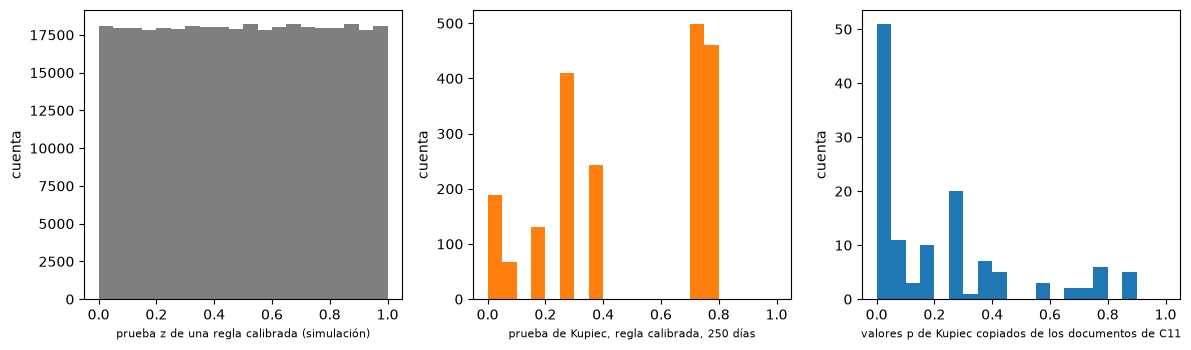

In [11]:
# Dibujar las tres distribuciones de valores p: la nula continua, la prueba de Kupiec del motor bajo su nula y los
# valores p reales de Q1
real = [c["value"] for r in q1["rows"] for c in r["cells"] if c["metric"] == "kupiec_1" and c["value"] is not None]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
panels = [
    (p.ravel(), "prueba z de una regla calibrada (simulación)", "tab:gray"),
    (kupiec_p, "prueba de Kupiec, regla calibrada, 250 días", "tab:orange"),
    (real, "valores p de Kupiec copiados de los documentos de C11", "tab:blue"),
]
for ax, (values, label, colour) in zip(axes, panels):
    ax.hist(values, bins=20, range=(0, 1), color=colour)
    ax.set_xlabel(label, fontsize=8)
    ax.set_ylabel("cuenta")
fig.tight_layout()
plt.show()

A la izquierda los valores p simulados son planos en los veinte tramos, como dice la ecuación. En el centro la prueba de Kupiec del motor bajo su nula se amontona en unos pocos valores, deja vacíos la mayoría de los tramos y pone bajo 0,05 más de lo que pondría un histograma plano. A la derecha los 126 valores p reales de Kupiec de Q1 (21 reglas en seis ventanas) no son planos en absoluto: el 40,5 por ciento cae bajo 0,05, porque las reglas reales no están calibradas en ventanas de estrés, y la figura no puede decir cuál está mejor calibrada, solo que muchas se rechazan. La figura muestra por qué el documento guarda estos números como contexto, en la página, y nunca en una clasificación. No muestra la regla que prueba dos cosas a la vez; el valor p de cobertura condicional tiene el mismo estatuto.

### Paso 6: las clasificaciones de una pregunta, recalculadas

El documento guarda, para cada métrica y columna, la fila o filas mejores (`standings`). Lo genera el paso, y un lector no debería aceptarlo por fe. La celda siguiente lo recalcula desde las celdas de una pregunta con la función escrita en el paso 3, usando solo las filas marcadas como clasificadas y la regla que declara cada métrica, y para `nearer-metric` el valor de referencia de la misma columna.

In [12]:
# Las clasificaciones de una pregunta recalculadas desde sus celdas con las reglas declaradas, sin ayuda de las del
# documento
def recompute(question):
    ranked = {r["id"] for r in question["rows"] if r["ranked"]}
    table = {}
    for row in question["rows"]:
        for c in row["cells"]:
            table.setdefault((c["metric"], c["column"]), {})[row["id"]] = c["value"]
    found = {}
    for metric in question["metrics"]:
        for column in metric["columns"]:
            values = {k: v for k, v in table.get((metric["id"], column), {}).items() if k in ranked}
            rule = metric["better"]
            reference = None
            if rule.startswith("nearer-metric:"):
                shown = [v for v in table[(rule.split(":")[1], column)].values() if isinstance(v, (int, float))]
                reference = float(shown[0])
            winners = best_cells(rule, values, reference)
            if winners is not None:
                found[(metric["id"], column)] = tuple(winners)
    return found

La función devuelve un diccionario de (métrica, columna) a la tupla de filas mejores. Se aplica a las doce preguntas en la celda siguiente, que afirma que el resultado es igual a las clasificaciones del documento, empates incluidos.

In [13]:
# Comparar mis clasificaciones con las del documento en las doce preguntas: deben coincidir, empates incluidos
rows = []
for qid, q in questions.items():
    mine = recompute(q)
    theirs = {(s["metric"], s["column"]): tuple(s["best"]) for s in q["standings"]}
    rows.append(
        {
            "Q": qid,
            "clasificaciones en el documento": len(theirs),
            "recalculadas aquí": len(mine),
            "iguales": mine == theirs,
            "empates": sum(len(v) > 1 for v in theirs.values()),
        }
    )
agreement = pd.DataFrame(rows).set_index("Q")
assert agreement["iguales"].all(), "las clasificaciones recalculadas difieren de las del documento"
print("preguntas que coinciden:", int(agreement["iguales"].sum()), "de", len(agreement))
agreement.T

preguntas que coinciden: 12 de 12


Q,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12
clasificaciones en el documento,21,26,6,12,6,24,30,12,9,3,6,12
recalculadas aquí,21,26,6,12,6,24,30,12,9,3,6,12
iguales,True,True,True,True,True,True,True,True,True,True,True,True
empates,7,3,5,4,0,0,0,0,3,0,0,0


La afirmación se cumple en las doce preguntas: 167 clasificaciones en el documento, 167 recalculadas aquí, 22 de ellas empates. Q1 tiene 21 clasificaciones para cuatro métricas clasificadas en seis ventanas, menos que las 24 que daría una malla completa, porque la métrica de zona no tiene un valor clasificable en tres de las ventanas (acciones 2020, tasas 2022 y mixto 2023: sus celdas dicen `not_evaluated`); Q7 tiene 30 y Q10 tiene 3. La coincidencia es lo que comprueba también la batería de pruebas del producto con un recálculo independiente, y significa que la lectura del documento es una función de sus celdas y de nada más. La tabla no muestra que las celdas sean correctas, que es el tema del paso siguiente. La celda siguiente llama al `standings_of` del propio paso sobre las celdas de Q1.

In [14]:
# La función de clasificaciones del propio paso sobre las celdas de Q1, frente al documento: mismas celdas, misma
# regla, misma respuesta
rows_q1 = [{"id": r["id"], "ranked": r["ranked"], "cells": r["cells"]} for r in q1["rows"]]
metrics_q1 = [{"id": m["id"], "better": m["better"], "columns": m["columns"]} for m in q1["metrics"]]
recomputed = bm.standings_of(metrics_q1, rows_q1)
print("clasificaciones del paso:", len(recomputed), "| iguales a las del documento:", recomputed == q1["standings"])
print(
    "Q1 clasifica:",
    len({m["id"] for m in q1["metrics"] if m["better"] != "none"}),
    "métricas y deja como contexto:",
    [m["id"] for m in q1["metrics"] if m["better"] == "none"],
)

clasificaciones del paso: 21 | iguales a las del documento: True
Q1 clasifica: 4 métricas y deja como contexto: ['expected_1', 'kupiec_1', 'cc_1']


La función del paso devuelve 21 clasificaciones sobre las celdas de Q1, y son iguales a las del documento. Q1 clasifica cuatro métricas (las dos pérdidas FZ0, la distancia del conteo de excedencias a su valor esperado, la zona) y deja tres como contexto: el conteo esperado, que es el objetivo de otra métrica, y los dos valores p. Las reglas y el documento coinciden, así que la pregunta siguiente es si las celdas mismas son los números de los documentos de los casos.

### Paso 7: seguir un valor citado hasta su origen

Cada valor del documento lleva `cited`: la ruta en el repositorio del archivo del que se copió, el puntero RFC 6901 del valor dentro de él y el SHA-256 del archivo (con los finales de línea normalizados a LF). La celda siguiente elige, para seis preguntas, la primera celda que cita un documento de caso versionado, abre ese archivo, resuelve el puntero con el `pointer_get` del propio constructor y compara el valor hallado con el valor del documento, y la huella del archivo con la citada.

In [15]:
# Seguir un valor citado hasta su origen: leer el archivo, resolver el puntero como lo hace el constructor, comparar
# el valor y la huella
def first_cited(question):
    for row in question["rows"]:
        for c in row["cells"]:
            if c["cited"] and c["cited"]["path"].startswith("data/derived/") and c["value"] is not None:
                return row["id"], c


columns = ["Q", "método", "archivo citado", "puntero", "documento", "en el puntero", "mismo valor", "misma huella"]
rows = []
for qid in ("Q1", "Q4", "Q5", "Q6", "Q7", "Q10"):
    method, c = first_cited(questions[qid])
    cited = c["cited"]
    found = bm.pointer_get(read_json(cited["path"]), cited["pointer"])
    same_hash = bm.sha256_of(ROOT / cited["path"]) == cited["sha256"]
    rows.append(
        (qid, method, cited["path"][13:], cited["pointer"][-34:], c["value"], found, found == c["value"], same_hash)
    )
pd.DataFrame(rows, columns=columns).set_index("Q")

,método,archivo citado,puntero,documento,en el puntero,mismo valor,misma huella
Q,,,,,,,
Q1,awhs,C11/calm-2004-06.json,tputs/models/2/by_level/0/fz0_mean,-4.490763,-4.490763,True,True
Q4,industry,C04/withdrawals.json,gns/0/treatments/0/coverage/5/rate,0.865000,0.865000,True,True
Q5,P1-scorecard,C01/holdout.json,/tests/26/metric,0.758722,0.758722,True,True
Q6,L0-km,C06/rd-2006-12.json,rung_comparison/0/integrated_brier,0.041392,0.041392,True,True
Q7,L1-ols,C08/dc-2003-06.json,/outputs/rung_comparison/0/rmse,0.296554,0.296554,True,True
Q10,lcr,C16/lcr-standard.json,tputs/scoring/denominators/0/ratio,0.506405,0.506405,True,True


Seis celdas de seis preguntas, tomadas de seis documentos de casos distintos, apuntan a un valor que es el mismo número y a un archivo cuya huella es la citada. El primer método de Q1, la simulación histórica ponderada por antigüedad, tiene una pérdida FZ0 media de $-4{,}490763$ en el puntero `/outputs/models/2/by_level/0/fz0_mean` de la ventana de calma de 2004 a 2006; el estimador de cohortes de Q4 que elimina los retiros de calificaciones cubre 0,865 en su posición del documento de retiros; la tarjeta de puntuación de Q5 tiene un AUC de Taiwán de 0,758722 en `/tests/26/metric`. La tabla muestra seis copias verificadas. No las muestra todas: la celda siguiente cuenta adónde apuntan las 1.844 celdas.

In [16]:
# Contar adónde apunta cada celda del documento: documentos de casos que el notebook puede abrir y archivos de
# manuscritos que no
where = Counter()
for c in cells:
    if c["cited"]:
        where[
            "data/derived" if c["cited"]["path"].startswith("data/derived/") else c["cited"]["path"].split("/")[0]
        ] += 1
    else:
        where["nula, sin cita"] += 1
print(dict(where))
manuscript_cells = Counter(
    q["id"]
    for q in questions.values()
    for r in q["rows"]
    for c in r["cells"]
    if c["cited"] and c["cited"]["path"].startswith("manuscripts/")
)
print("celdas que citan un archivo de manuscrito, por pregunta:", dict(sorted(manuscript_cells.items())))
print(
    "archivos distintos leídos por el constructor:",
    len(document["provenance"]["documents"]),
    "| regla de la huella:",
    document["provenance"]["hash_rule"],
)

{'data/derived': 1618, 'nula, sin cita': 26, 'manuscripts': 200}
celdas que citan un archivo de manuscrito, por pregunta: {'Q11': 15, 'Q2': 122, 'Q9': 63}
archivos distintos leídos por el constructor: 48 | regla de la huella: SHA-256 of the file with line endings normalised to LF


De las 1.844 celdas, 1.618 citan un documento de caso versionado que el notebook puede abrir, 200 citan un archivo de resultados de un manuscrito bajo `manuscripts/` (los experimentos de las preguntas 2, 9 y 11, con 122, 63 y 15 celdas, que un notebook no puede leer) y 26 son nulas sin cita. El constructor leyó 48 archivos distintos en total, y la regla de la huella está dicha en el documento: el SHA-256 del archivo con los finales de línea normalizados a LF, de modo que una copia de trabajo en Windows tiene la misma huella que una en Linux. Las pruebas del producto releen cada celda en cada corrida, así que un caso reconstruido cuyos números se movieron falla hasta que se vuelva a correr el paso; este notebook sigue seis. La cuenta muestra la procedencia de todo el documento. No verifica las 200 celdas de manuscritos, que otro lector debe abrir.

### Paso 8: leer la comparación

Cuatro vistas leen el documento. La primera son las barras de una métrica de una pregunta por método, agrupadas por categoría: la pérdida FZ0 media al nivel del 1 por ciento de los 18 métodos de Q1 que tienen la pérdida (10 de larga data, 5 publicados recientemente y 3 propuestos) en la ventana de acciones de 2007 a 2009, con la mejor marcada.

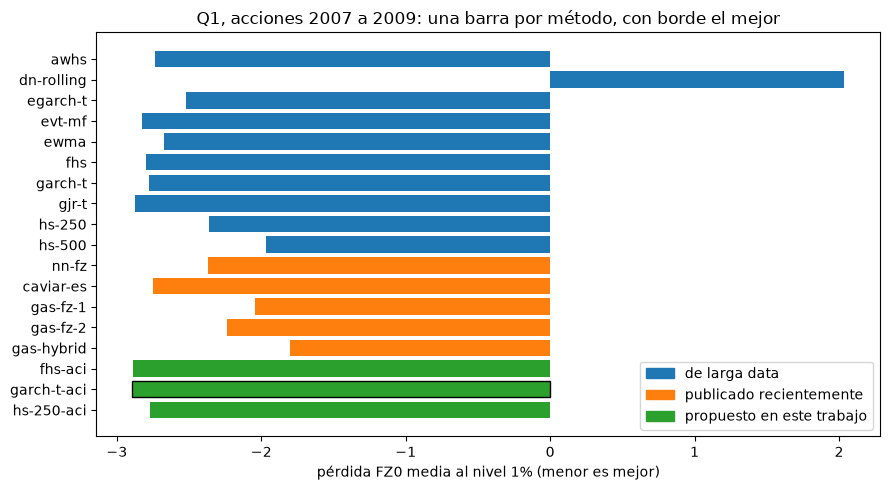

In [17]:
# Barras de una métrica de una pregunta por método: la pérdida FZ0 media de los métodos de Q1 en una ventana,
# agrupados por categoría
metric, window = "fz0_1", "equity-2007-09"
values = {
    r["id"]: next((c["value"] for c in r["cells"] if c["metric"] == metric and c["column"] == window), None)
    for r in q1["rows"]
}
standing = {r["id"]: r["standing"] for r in q1["rows"]}
order = [k for s in ("established", "recent", "proposed") for k in values if standing[k] == s and values[k] is not None]
best = next(s["best"] for s in q1["standings"] if s["metric"] == metric and s["column"] == window)
colour = {"established": "tab:blue", "recent": "tab:orange", "proposed": "tab:green"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    order,
    [values[k] for k in order],
    color=[colour[standing[k]] for k in order],
    edgecolor=["black" if k in best else "none" for k in order],
)
ax.invert_yaxis()
ax.set_xlabel("pérdida FZ0 media al nivel 1% (menor es mejor)")
ax.set_title("Q1, acciones 2007 a 2009: una barra por método, con borde el mejor")
handles = [plt.Rectangle((0, 0), 1, 1, color=colour[s]) for s in colour]
ax.legend(handles, [STANDING[s] for s in colour], loc="lower right")
fig.tight_layout()
plt.show()

Las barras están agrupadas por categoría: los métodos de larga data en azul, los publicados recientemente en naranja y los tres propuestos en este trabajo en verde, y la mejor, con borde negro, es el GARCH(1,1) propuesto con errores t de Student y recalibración conforme adaptativa (`garch-t-aci`), con una pérdida de $-2{,}894$, seguido por la simulación histórica filtrada propuesta con la misma recalibración (`fhs-aci`) en $-2{,}886$ y por un GJR-GARCH de larga data (`gjr-t`) en $-2{,}876$. Las barras llevan los identificadores de las filas del documento. Una pérdida menor es mejor, así que una barra más larga hacia la izquierda es mejor. Los métodos de un grupo no están agrupados en un extremo: el tercer método propuesto tiene cuatro barras de larga data por encima, así que el grupo dice cuán antiguo es un método y no cuán bien lo hace. La primera brecha, 0,008, es además una que el redondeo de la sección siguiente volvería un empate si se redondeara a dos decimales; a los tres decimales de la sección siguiente no lo es. La figura muestra una métrica en una ventana. El mismo método es además el mejor en una ventana más (mixto 2023) y no lo es en las otras cuatro, como dicen las clasificaciones del documento.

La segunda vista hace la pregunta que el documento existe para responder sobre los métodos propios del producto: con qué frecuencia un método propuesto en este trabajo es el mejor en una métrica clasificada, y con cuál no lo es. La celda siguiente cuenta, para cada pregunta que tiene un método propuesto clasificado, las celdas clasificadas (métrica por columna) cuya mejor fila es una propuesta, empates incluidos.

In [18]:
# Con qué frecuencia un método propuesto en este trabajo es el mejor en una métrica clasificada, desde las
# clasificaciones donde tiene valor
rows = []
for qid, q in questions.items():
    proposed = {r["id"] for r in q["rows"] if r["standing"] == "proposed" and r["ranked"]}
    has_value = {
        (c["metric"], c["column"])
        for r in q["rows"]
        if r["id"] in proposed
        for c in r["cells"]
        if c["value"] is not None
    }
    scored = [s for s in q["standings"] if (s["metric"], s["column"]) in has_value]
    won = sum(bool(proposed & set(s["best"])) for s in scored)
    rows.append(
        {
            "Q": qid,
            "métodos propuestos": len(proposed),
            "celdas clasificadas": len(scored),
            "mejor": won,
            "no mejor": len(scored) - won,
        }
    )
proposed_table = pd.DataFrame(rows).set_index("Q")
print("celdas clasificadas donde un método propuesto tiene valor:", int(proposed_table["celdas clasificadas"].sum()))
print("mejor:", int(proposed_table["mejor"].sum()), "| no mejor:", int(proposed_table["no mejor"].sum()))
print("preguntas sin método propuesto:", proposed_table.index[proposed_table["métodos propuestos"] == 0].tolist())
proposed_table.T

celdas clasificadas donde un método propuesto tiene valor: 75
mejor: 30 | no mejor: 45
preguntas sin método propuesto: ['Q5', 'Q6', 'Q7', 'Q8', 'Q10', 'Q12']


Q,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12
métodos propuestos,3,3,2,1,0,0,0,0,1,0,3,0
celdas clasificadas,18,24,6,12,0,0,0,0,9,0,6,0
mejor,7,3,5,8,0,0,0,0,4,0,3,0
no mejor,11,21,1,4,0,0,0,0,5,0,3,0


Seis de las doce preguntas (Q5, Q6, Q7, Q8, Q10 y Q12) no tienen un método propuesto clasificado: comparan métodos de larga data y publicados recientemente, y el documento las conserva por esa razón. En las seis que tienen uno hay 75 celdas clasificadas en las que un método propuesto tiene valor (la definición del propio constructor de una celda puntuada), y un método propuesto es el mejor en 30 de ellas y no es el mejor en 45. La división es desigual: Q4 tiene 8 de 12, Q3 tiene 5 de 6, Q9 tiene 4 de 9, Q1 tiene 7 de 18, Q11 tiene 3 de 6 y Q2 tiene 3 de 24. La tabla cuenta celdas y no preguntas, así que una pregunta con muchas columnas pesa más. No dice por qué un método propuesto pierde donde pierde, lo que dicen las dos celdas siguientes y los manuscritos.

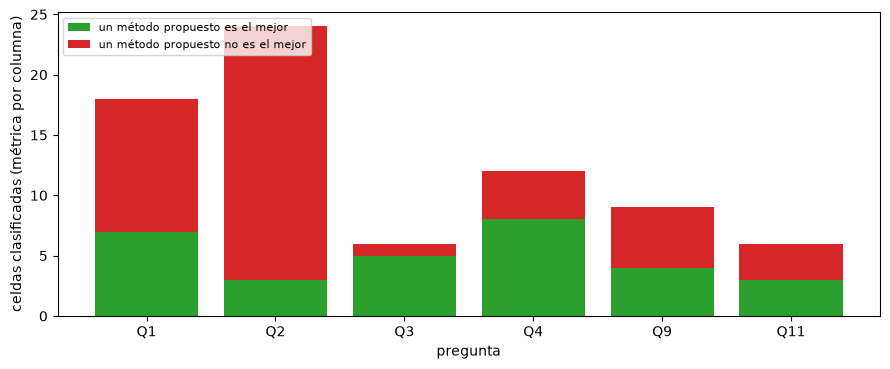

In [19]:
# Dibujar la tabla anterior: por pregunta, las celdas donde un método propuesto es el mejor y donde no lo es
shown = proposed_table[proposed_table["celdas clasificadas"] > 0]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(shown.index, shown["mejor"], color="tab:green", label="un método propuesto es el mejor")
ax.bar(
    shown.index, shown["no mejor"], bottom=shown["mejor"], color="tab:red", label="un método propuesto no es el mejor"
)
ax.set_xlabel("pregunta")
ax.set_ylabel("celdas clasificadas (métrica por columna)")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

El verde es la parte de las celdas clasificadas de cada pregunta donde un método propuesto es el mejor, y el rojo la parte donde no lo es. Q3 es casi todo verde y Q2 casi todo rojo; Q4 es dos tercios verde; Q1 es verde en 7 de sus 18 celdas. La figura muestra de una vez el cuadro completo de los métodos propios del producto, pérdidas incluidas, y es para lo que sirve el documento: un método propuesto en este trabajo que no gana se muestra sin ganar. No muestra el tamaño de ninguna pérdida o victoria, solo si ocurrió una. La celda siguiente nombra cada pérdida con palabras, con el DOI de concepto del manuscrito que la informa.

In [20]:
# Cada resultado negativo en palabras, con el DOI de concepto del manuscrito que lo informa
for q in questions.values():
    for item in q["negative_results"]:
        print(q["id"], "|", ", ".join(item["rows"]), "|", "https://doi.org/" + item["concept_doi"])
        print("   ", item["text"][LANG])

Q2 | e_rate, e_cluster, e_battery | https://doi.org/10.5281/zenodo.24053173
    El manuscrito reporta un resultado parcial: el tamaño se mantiene bajo parada opcional, pero las cláusulas de retraso y de costo de potencia no se cumplen con una tasa de excesos de tres veces en veinte semillas y sí con cuatro veces.
Q4 | anchored | https://doi.org/10.5281/zenodo.24053159
    El veredicto versionado es refutado en ambas cláusulas: el intervalo anclado no cubre mejor que la banda de Manski, que cubre igual de seguido con un intervalo más ancho, y el parámetro anclado no es estable entre años.
Q9 | engine | https://doi.org/10.5281/zenodo.24053161
    La prueba de brecha como el motor lee un parámetro declarado señala cambios no relacionados muy por encima del 5% nominal, donde las pruebas de quiebre calibradas se quedan cerca; la tabla la muestra perdiendo en falsas alertas.
Q11 | shift-permutation | https://doi.org/10.5281/zenodo.24053187
    La referencia por permutación detecta un cambio 

Se listan cuatro resultados negativos, uno por cada pregunta donde un método propuesto pierde y el manuscrito lo dice: Q2, donde los monitores de e-proceso mantienen su tamaño bajo parada opcional pero no cumplen las cláusulas de retraso y de costo de potencia con una tasa de aciertos de tres veces (https://doi.org/10.5281/zenodo.24053173); Q4, donde el intervalo anclado es refutado en ambas cláusulas (https://doi.org/10.5281/zenodo.24053159); Q9, donde la prueba de quiebre del motor marca cambios no relacionados muy por encima del 5 por ciento nominal (https://doi.org/10.5281/zenodo.24053161); y Q11, donde la referencia de permutación detecta un desplazamiento de dos desviaciones estándar con menos frecuencia que la caída fija de 0,05 (https://doi.org/10.5281/zenodo.24053187). El texto de cada uno es el del documento, en el idioma del árbol. Los títulos de los manuscritos viven en `product.json`, que un notebook no puede leer, así que los enlaces son los DOI de concepto que lleva el documento. La celda no dice cuál manuscrito es mejor, solo cuál informa una pérdida.

La tercera vista es el estado de verdad de cada corrida, un hecho copiado de los documentos de casos que cita la corrida y, para una corrida que cita solo archivos de manuscritos, declarado con su razón. Dice a un lector qué significa ganar: en `real-outcomes` la métrica se mide sobre lo que ocurrió; en `synthetic-known-truth` se mide contra un generador cuya verdad fija el experimentador; en `synthetic-calibrated` los datos se moldean a un evento real. La celda siguiente cuenta las corridas y las clasificaciones por estado.

In [21]:
# El estado de verdad de cada corrida: en qué descansan sus datos, cuántas clasificaciones vienen de cada tipo y
# dónde gana un método propuesto
runs = pd.DataFrame(
    [{"Q": q["id"], "run": r["id"], "status": r["truth_status"]} for q in questions.values() for r in q["runs"]]
)
run_of = {(q["id"], m["id"]): m["run_id"] for q in questions.values() for m in q["metrics"]}
status_of = {(q["id"], r["id"]): r["truth_status"] for q in questions.values() for r in q["runs"]}
per_standing = Counter(
    status_of[(q["id"], run_of[(q["id"], s["metric"])])] for q in questions.values() for s in q["standings"]
)
winners = {}
for q in questions.values():
    proposed = {r["id"] for r in q["rows"] if r["standing"] == "proposed" and r["ranked"]}
    for s in q["standings"]:
        if proposed & set(s["best"]):
            winners.setdefault(status_of[(q["id"], run_of[(q["id"], s["metric"])])], set()).add(q["id"])
print("corridas por estado de verdad:", runs["status"].value_counts().to_dict())
print("clasificaciones por estado de verdad:", dict(per_standing))
print(
    "preguntas donde un método propuesto es el mejor en algún lugar, por estado de verdad:",
    {k: sorted(v, key=lambda x: int(x[1:])) for k, v in winners.items()},
)
runs.groupby("status")["Q"].apply(lambda s: ", ".join(sorted(set(s)))).to_frame("preguntas")

corridas por estado de verdad: {'synthetic-known-truth': 9, 'real-outcomes': 8, 'synthetic-calibrated': 1}
clasificaciones por estado de verdad: {'real-outcomes': 93, 'synthetic-known-truth': 71, 'synthetic-calibrated': 3}
preguntas donde un método propuesto es el mejor en algún lugar, por estado de verdad: {'real-outcomes': ['Q1'], 'synthetic-known-truth': ['Q2', 'Q3', 'Q4', 'Q9', 'Q11']}


,preguntas
status,
real-outcomes,"Q1, Q12, Q2, Q5, Q6, Q7"
synthetic-calibrated,Q10
synthetic-known-truth,"Q11, Q2, Q3, Q4, Q8, Q9"


De las 18 corridas, 9 descansan sobre un generador de verdad conocida, 8 sobre desenlaces reales y una, el estrés inverso de liquidez de Q10, sobre una corrida sintética calibrada. De las clasificaciones del documento, 93 vienen de desenlaces reales, 71 de verdad conocida y 3 de la corrida calibrada. El estado cambia cómo se lee una victoria. Un método propuesto que gana en un generador (Q2, Q3, Q4, Q9, Q11) ha mostrado que recupera una verdad que fijó el experimentador; uno que gana en ventanas reales (Q1) lo ha mostrado en la única historia que ocurrió; y una pregunta que mezcla los tipos, como hace Q2, los conserva como corridas separadas y nunca clasifica las reales. La tabla lista las preguntas por estado. No dice si un generador se parece al mundo, lo que es una pregunta del diseño de cada caso.

La cuarta vista cuenta las celdas nulas. Una celda que el producto no tiene es nula, con su razón, y nada se estima en su lugar. La celda siguiente las cuenta por la razón que da el documento y por pregunta.

In [22]:
# Contar las celdas nulas por la razón que da el documento y por pregunta
nulls = [
    (q["id"], c["null_reason"][LANG])
    for q in questions.values()
    for r in q["rows"]
    for c in r["cells"]
    if c["value"] is None
]
reasons = Counter(reason for _, reason in nulls)
print(
    "celdas nulas:",
    len(nulls),
    "| razones distintas:",
    len(reasons),
    "| celdas nulas sin razón:",
    sum(not r for _, r in nulls),
)
by_question = pd.Series(Counter(qid for qid, _ in nulls)).reindex(list(questions)).fillna(0).astype(int)
for reason, n in reasons.most_common(4):
    print(n, "|", reason[:110])

celdas nulas: 150 | razones distintas: 14 | celdas nulas sin razón: 0
37 | la serie mediana nunca se señala dentro del horizonte
36 | la regla no pronostica la pérdida esperada de cola, así que su pérdida FZ0 no está definida
18 | el documento del caso no trae un valor p para este modelo en esta ventana e indica: no evaluado: sin excesos
18 | el bloque conformal no trae la zona de Basilea


Hay 150 celdas nulas y 14 razones distintas, y ninguna celda nula carece de su razón. La más común es que el flujo mediano nunca se marca dentro del horizonte (37 celdas: un monitor que nunca se dispara no tiene día de primera marca), luego que la regla no pronostica pérdida esperada de cola, así que su pérdida FZ0 no está definida (36), que el documento del caso no da un valor p para un modelo en una ventana y dice que no se evaluó por no tener excedencias (18), y que el bloque conforme no lleva zona de Basilea (18). Cada una dice por qué falta un número y ninguna es un cero. La figura siguiente las dibuja contra todas las celdas.

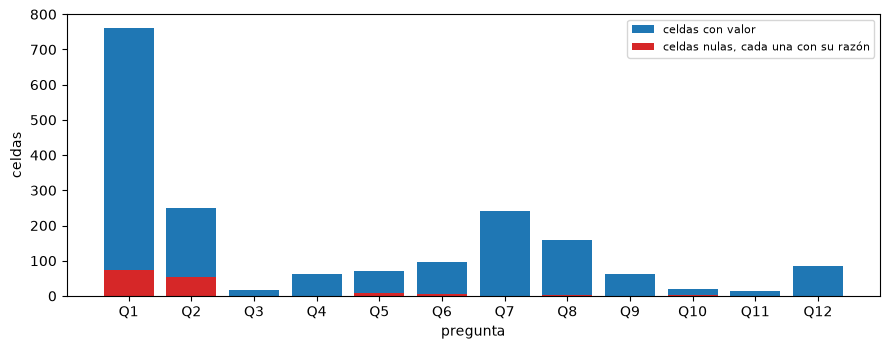

In [23]:
# Dibujar las celdas nulas contra todas las celdas de cada pregunta
total = pd.Series({q["id"]: sum(len(r["cells"]) for r in q["rows"]) for q in questions.values()})
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(total.index, total.values, color="tab:blue", label="celdas con valor")
ax.bar(by_question.index, by_question.values, color="tab:red", label="celdas nulas, cada una con su razón")
ax.set_xlabel("pregunta")
ax.set_ylabel("celdas")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

El rojo es la parte de celdas nulas dentro de las celdas de cada pregunta. Q1 (75 de 762 celdas) y Q2 (54 de 250) llevan 129 de las 150, porque sus métodos difieren más en lo que pueden pronosticar: una regla sin pronóstico de pérdida esperada de cola no tiene pérdida FZ0, y un monitor que nunca se dispara no tiene retraso. Un nulo nunca se clasifica ni se reemplaza, así que un método con nulos compite en menos columnas, y la clasificación que ve el lector es sobre las celdas que existen. La figura muestra dónde viven los nulos. No muestra si un nulo oculta una debilidad: un método cuyas mejores columnas son las únicas que tiene se clasifica solo por su fortaleza, y las notas de cada fila del documento lo dicen donde importa.

### Dónde falla la comparación

La comparación solo informa tanto como sus reglas, y cinco cosas limitan lo que dice. Cada una se muestra con código sobre el documento.

**Un redondeo que oculta un empate.** La regla de empate es la igualdad exacta de los números guardados, y la página muestra números redondeados. La celda siguiente recorre las 167 clasificaciones en busca de las columnas donde los dos mejores valores exactos difieren y coinciden una vez redondeados a tres decimales.

In [24]:
# Dónde un redondeo oculta un empate: las columnas donde los dos mejores valores exactos difieren pero coinciden a
# tres decimales
hidden = []
for qid, q in questions.items():
    ranked = {r["id"] for r in q["rows"] if r["ranked"]}
    table = {}
    for row in q["rows"]:
        for c in row["cells"]:
            table.setdefault((c["metric"], c["column"]), {})[row["id"]] = c["value"]
    for s in q["standings"]:
        metric = next(m for m in q["metrics"] if m["id"] == s["metric"])
        if metric["better"] not in ("lower", "higher") or s["tie"]:
            continue
        numbers = sorted(
            (v for k, v in table[(s["metric"], s["column"])].items() if k in ranked and isinstance(v, (int, float))),
            reverse=metric["better"] == "higher",
        )
        if len(numbers) > 1 and numbers[0] != numbers[1] and round(numbers[0], 3) == round(numbers[1], 3):
            hidden.append((qid, s["metric"], s["column"], numbers[0], numbers[1]))
exact_ties = sum(s["tie"] for q in questions.values() for s in q["standings"])
print(
    "clasificaciones en total:",
    sum(len(q["standings"]) for q in questions.values()),
    "| empates exactos declarados:",
    exact_ties,
)
print("columnas donde los dos mejores difieren pero coinciden a tres decimales:", len(hidden))
pd.DataFrame(hidden[:6], columns=["Q", "metric", "column", "mejor", "segundo"])

clasificaciones en total: 167 | empates exactos declarados: 22
columnas donde los dos mejores difieren pero coinciden a tres decimales: 21


,Q,metric,column,mejor,segundo
0,Q1,fz0_25,calm-2004-06,-4.658793,-4.658646
1,Q4,width,first_year,0.009690,0.010339
2,Q4,width,capture70,0.009690,0.010339
3,Q4,width,first_year_x10,0.003079,0.003277
4,Q5,tw_brier,holdout,0.135933,0.136100
5,Q6,ibs,2006-12,0.041187,0.041364


De las 167 clasificaciones, 22 son empates exactos, y en 21 columnas más los dos mejores valores difieren pero se leen igual a tres decimales. En la pérdida al 2,5 por ciento de la ventana de calma de Q1 los dos mejores son $-4{,}658793$ y $-4{,}658646$; en Q4 los mejores anchos de intervalo son 0,009690 y 0,010339, ambos 0,010; en Q5 las puntuaciones de Brier de Taiwán son 0,135933 y 0,136100, ambas 0,136; y en Q6 las puntuaciones de Brier integradas son 0,041187 y 0,041364, ambas 0,041. Un lector que redondea ve un empate donde el documento nombra un ganador, y un lector que confía en el ganador ve una diferencia cuyo tamaño frente al ruido propio de la corrida el documento no mide. El documento conserva el número exacto y la regla de empate; no afirma que la diferencia sea significativa. La tabla muestra dónde el ganador es cuestión del cuarto decimal.

**Una métrica que es contexto.** Los valores p se mantienen fuera de las clasificaciones porque no son puntuaciones. La celda siguiente pregunta cuál sería el ganador de cada ventana de Q1 si el valor p de Kupiec se clasificara como mayor es mejor, y lo compara con el ganador por la pérdida FZ0 que el documento sí clasifica.

In [25]:
# Una métrica que el documento guarda como contexto: el valor p de Kupiec clasificado como mayor es mejor, con
# empates, frente a los ganadores FZ0
rows = []
for window in q1["metrics"][0]["columns"]:
    p_by_rule = {
        r["id"]: next(c["value"] for c in r["cells"] if c["metric"] == "kupiec_1" and c["column"] == window)
        for r in q1["rows"]
        if r["ranked"]
    }
    fz0_best = next(s["best"] for s in q1["standings"] if s["metric"] == "fz0_1" and s["column"] == window)
    by_p = best_cells("higher", p_by_rule)
    rows.append(
        {
            "ventana": window,
            "mejor por la pérdida FZ0": ", ".join(fz0_best),
            "métodos empatados en el mejor p": len(by_p),
            "ganador FZ0 entre ellos": bool(set(fz0_best) & set(by_p)),
        }
    )
table = pd.DataFrame(rows).set_index("ventana")
missed = int((~table["ganador FZ0 entre ellos"]).sum())
print("ventanas donde el ganador FZ0 no está entre los métodos con el mejor p:", missed, "/", len(table))
table

ventanas donde el ganador FZ0 no está entre los métodos con el mejor p: 4 / 6


,mejor por la pérdida FZ0,métodos empatados en el mejor p,ganador FZ0 entre ellos
ventana,,,
calm-2004-06,gjr-t,5,False
equity-2007-09,garch-t-aci,1,True
equity-2020,fhs,4,True
rates-2022,ewma,3,False
fx-2008,caviar-es,6,False
mixed-2023,garch-t-aci,1,False


En cuatro de las seis ventanas el ganador FZ0 no está entre los métodos con el mejor valor p de Kupiec. Con los empates conservados, el mejor p lo comparten 5 métodos en la ventana de calma, 4 en 2020, 3 en 2022 y 6 en 2008, y lo tiene un solo método en las otras dos ventanas: acciones 2007 a 2009, donde es también el ganador FZ0 (el GARCH conforme adaptativo propuesto), y mixto 2023, donde es otro método. En 2020 el ganador FZ0 está dentro del conjunto empatado. Una clasificación por valor p corona por tanto grupos de métodos y no ganadores. La tabla muestra el desacuerdo entre una puntuación y una prueba. No muestra cuál de los dos ordena el mejor pronóstico; la página conserva ambos, uno como clasificación y el otro como contexto.

**Corridas que no deben mezclarse.** Q2 mantiene separadas dos corridas de generador, el generador del caso (semilla 42) y el generador del manuscrito (semilla 20261104), cada una con sus propios archivos. La celda siguiente lista la mejor regla por columna para el día mediano de primera marca en cada una y comprueba que ningún archivo sirve a ambas.

In [26]:
# Dos corridas que no deben mezclarse: los ganadores de Q2 con el generador del caso (semilla 42) y con el del
# manuscrito
q2 = questions["Q2"]
rows = []
for metric in ("gen_median", "man_median"):
    for s in (s for s in q2["standings"] if s["metric"] == metric):
        rows.append({"métrica": metric, "columna": s["column"], "mejor": ", ".join(s["best"]), "valor": s["value"]})
table = pd.DataFrame(rows)
seeds = {r["id"]: r["seed"]["value"] if r["seed"] else None for r in q2["runs"]}
files = {r["id"]: set(r["files"]) for r in q2["runs"]}
print("semillas de las corridas de Q2:", seeds)
print("archivos que comparten dos corridas de Q2:", sorted(files["generator"] & files["manuscript"]))
same = [c for c in table["columna"].unique() if table[(table["columna"] == c)]["mejor"].nunique() == 1]
print("columnas donde ambas corridas nombran el mismo mejor método:", len(same), "de", table["columna"].nunique())
table.pivot(index="columna", columns="métrica", values="mejor")

semillas de las corridas de Q2: {'generator': 42, 'manuscript': 20261104, 'real-windows': None, 'vintages': None}
archivos que comparten dos corridas de Q2: []
columnas donde ambas corridas nombran el mismo mejor método: 5 de 6


métrica,gen_median,man_median
columna,,
cluster-0.1,kupiec_trailing,kupiec_trailing
cluster-0.2,kupiec_trailing,independence_trailing
cluster-0.4,kupiec_cumulative,kupiec_cumulative
rate-x2,traffic_light,traffic_light
rate-x3,kupiec_cumulative,kupiec_cumulative
rate-x4,kupiec_cumulative,kupiec_cumulative


Las dos corridas no comparten ningún archivo, y en cinco de las seis columnas nombran la misma mejor regla. En la columna `cluster-0.2` no: el generador del caso nombra la prueba de Kupiec móvil y el generador del manuscrito la prueba de independencia móvil. Si las dos se mezclaran en una columna el documento tendría que elegir, o promediar dos semillas de dos generadores que difieren en el diseño; mantenerlas separadas deja ver que el orden es estable en cinco de seis celdas y no en la sexta. La tabla muestra una coincidencia que la mezcla habría ocultado. No dice cuál generador está más cerca de los flujos reales, y por eso las ventanas y las cohortes reales de Q2 se muestran y nunca se clasifican.

**Un método dejado fuera, y por qué.** No todo método del producto está en una pregunta. El documento lista cuatro métodos que deja fuera de toda pregunta y dos preguntas que no construye, cada una con su razón. La celda siguiente los imprime.

In [27]:
# Los métodos que el documento deja fuera de toda pregunta y las preguntas que no construye, con sus razones en
# palabras
for item in document["left_out"]:
    print("-", item["method"][LANG], ":", item["reason"][LANG][:150])
for item in document["not_built"]:
    print("-", item["id"], item["title"][LANG], ":", item["reason"][LANG][:150])

- Motor de pérdida crediticia esperada de IFRS 9 : Ningún método competidor corre sobre un protocolo: la pérdida ponderada por escenarios está versionada junto a la pérdida de la trayectoria media, per
- Satélites de pronóstico condicional y de cuantil de crecimiento en riesgo : No hay números versionados: el documento de estrés trae solo los satélites lineales y probit.
- Calibración de la curva de PD llevada a un período nuevo : Los enfoques escalados toman la PD del período nuevo como entrada, así que no hay nada que clasificar (la pregunta 13 no se construye).
- Los estudios publicados de tamaño y potencia de las pruebas de validación, repetidos : Reproducen celdas publicadas y no compiten con otro método sobre una serie común.
- Q13 Curva de PD llevada a un período nuevo : Los enfoques escalados reciben la PD del período nuevo como entrada y reescalan la curva, así que su pronóstico es igual a la PD observada y no se pue
- Q14 Cuantil de pérdida de cartera por método : No existe u

Los cuatro métodos dejados fuera tienen cuatro razones: el motor de pérdida crediticia esperada de IFRS 9 no tiene un desenlace que puntuar ni un método competidor sobre un protocolo; los satélites de cuantiles de crecimiento en riesgo no tienen números versionados; la calibración de una curva de PD llevada a un período nuevo toma la PD del período nuevo como entrada, así que no hay nada que clasificar; y los estudios publicados de tamaño y potencia de las pruebas de validación reproducen celdas publicadas y no compiten con otro método sobre un flujo común. Las dos preguntas no construidas, Q13 y Q14, dicen que el pronóstico de los enfoques escalados es igual a la PD observada, y que no existe una verdad para un cuantil de pérdida de cartera, así que solo se puede comparar la dispersión. Un método ausente de la comparación no es por ello más débil, y la comparación no dice nada de él. La lista muestra los bordes de lo que cubre el documento. No dice si una versión posterior los llena.

**Una categoría dice cuán antiguo es un método, no cuán bueno.** Las palabras de la página (de larga data, publicado recientemente, propuesto en este trabajo) vienen del origen registrado en la fila del método en el diseño del producto, leído por código y nunca escrito por fila. Clasifican el origen de un método. La celda siguiente cuenta, en todas las preguntas, cuántas filas clasificadas tiene cada categoría y cuántas clasificaciones ganan sus filas, con los empates contados para cada método empatado.

In [28]:
# Una categoría dice cuán antiguo es un método: cuántas filas clasificadas tiene cada una y cuántas clasificaciones
# gana, empates contados
standing_of = {(q["id"], r["id"]): r["standing"] for q in questions.values() for r in q["rows"] if r["ranked"]}
wins = Counter(
    standing_of[(q["id"], b)]
    for q in questions.values()
    for s in q["standings"]
    for b in s["best"]
    if (q["id"], b) in standing_of
)
size = Counter(standing_of.values())
table = pd.DataFrame({"filas clasificadas": size, "clasificaciones ganadas": wins}).fillna(0).astype(int)
table["victorias por fila"] = (table["clasificaciones ganadas"] / table["filas clasificadas"]).round(2)
table.index = [STANDING[s] for s in table.index]
table

,filas clasificadas,clasificaciones ganadas,victorias por fila
de larga data,44,133,3.02
publicado recientemente,24,45,1.88
propuesto en este trabajo,13,40,3.08
referencia,7,10,1.43


Las 44 filas de larga data ganan 133 clasificaciones, 3,02 por fila; las 13 filas propuestas ganan 40, 3,08 por fila; las 24 filas publicadas recientemente ganan 45, 1,88 por fila; y las 7 filas de referencia ganan 10, 1,43 por fila. Las tasas de las filas de larga data y de las propuestas son casi iguales y muy superiores a las de las publicadas recientemente: la etiqueta no ordena nada: las filas publicadas recientemente ganan menos, y las más antiguas y las más nuevas ganan igual. Estas cuentas dependen además de dónde se ingresa una fila: una fila en una pregunta con muchas columnas gana más. La tabla dice que una categoría es una etiqueta de origen y que de ella no se sigue ningún orden de calidad. No dice que un método propuesto sea mejor, y las secciones anteriores mostraron que no siempre lo es.

### Úsalo con tus propios datos

Para colocar un método propio junto a las filas de una pregunta necesitas tres cosas: el protocolo de la pregunta (la partición, la semilla, la métrica y las filas sobre las que se puntúa), las predicciones de tu método sobre exactamente esas filas, y la regla de la pregunta para la métrica. El entorno aislado de un notebook guarda los documentos versionados y nada más, así que la pregunta elegida aquí es Q5, la corrida alemana: su protocolo puntúa cada escalón sobre una reserva bloqueada de 300 solicitantes, y el gemelo versionado guarda solo una muestra de 50 solicitantes con la PD de la tarjeta de puntuación, el logit del EBM, los desenlaces y los insumos del modelo. Los insumos de los otros 250 solicitantes de la reserva no están en el entorno, ni tampoco las predicciones de los otros escalones. Un método propio no puede por tanto puntuarse aquí sobre el protocolo exacto de la pregunta. Lo que se puede hacer con honestidad es puntuarlo a él, y a la tarjeta de puntuación versionada, sobre los 50 solicitantes, mostrar esa tabla aparte y decir que no es una fila de la comparación del documento. La celda siguiente construye una regla transparente propia, una logística de la duración, el monto del crédito y la tasa de cuota con coeficientes fijados a mano (sin ajuste, sin fuga), y lee la muestra versionada.

In [29]:
# Los 50 solicitantes del gemelo alemán que guarda el entorno, con los insumos de una regla transparente propia
twin = read_json("data/derived/C01/german-twin.json")
sample = twin["outputs"]["sample"]
y = np.array(sample["targets"])
score = np.array(sample["scorecard_pd"])
inputs = pd.DataFrame(sample["inputs"])
my_logit = (
    -2.4 + 0.035 * inputs["duration_months"] + 0.00012 * inputs["credit_amount"] + 0.15 * inputs["installment_rate"]
)
mine = (1 / (1 + np.exp(-my_logit))).to_numpy()
policy = default_policy()
print("versión del motor que horneó el documento:", twin["provenance"]["riskvalidation_version"])
holdout_n = next(r["n"] for r in twin["tests"] if r["model_id"] == "P1-scorecard" and r["test_id"] == "disc.auc")
print("filas de la reserva detrás de la corrida alemana del documento:", holdout_n, "| filas de la muestra:", len(y))
print(
    "incumplimientos en la muestra:",
    int(y.sum()),
    "| PD media: tarjeta de puntuación, mi regla:",
    round(float(score.mean()), 4),
    round(float(mine.mean()), 4),
)

versión del motor que horneó el documento: 1.1.0
filas de la reserva detrás de la corrida alemana del documento: 300 | filas de la muestra: 50
incumplimientos en la muestra: 12 | PD media: tarjeta de puntuación, mi regla: 0.2601 0.3209


La corrida alemana del documento descansa sobre 300 filas de la reserva y la muestra tiene 50. Los 50 son las primeras 50 filas de esa reserva: `data-pipeline/pipeline/cases/c01_retail_pd.py` escribe la muestra del gemelo alemán desde las primeras 50 posiciones de su conjunto de evaluación (`pos[:50]`), y para esa variante el conjunto de evaluación es la reserva (`evaluation_set` devuelve `fit.sp.holdout`). Son por tanto un subconjunto con n = 50, no toda la reserva, y su PD media de la tarjeta de puntuación es 0,2601 con 12 incumplimientos; mi regla tiene una PD media de 0,3209. La celda siguiente imprime sola la fila del documento para la tarjeta de puntuación y luego calcula con el motor las tres métricas clasificadas de la pregunta, el AUC (mayor), la puntuación de Brier (menor) y el error de calibración esperado (menor), para la tarjeta de puntuación y para mi regla sobre los 50, en una tabla aparte.

In [30]:
# La fila del documento para la tarjeta de puntuación sobre su reserva, mostrada sola; luego las tres métricas
# clasificadas sobre los 50 solicitantes, aparte
document_rows = {r["id"]: {c["metric"]: c["value"] for c in r["cells"]} for r in q5["rows"]}
reference = {
    "AUC": document_rows["P1-scorecard"]["de_auc"],
    "Brier": document_rows["P1-scorecard"]["de_brier"],
    "ECE": document_rows["P1-scorecard"]["de_ece"],
}
print(
    "documento, corrida alemana, tarjeta de puntuación, n = " + str(holdout_n),
    {k: round(v, 4) for k, v in reference.items()},
)
on_50 = {}
for name, values in (("tarjeta", score), ("mi regla", mine)):
    on_50[name] = {
        "AUC": disc.disc_auc(values, y, policy=policy).metric,
        "Brier": cal.pd_brier(y, values, policy=policy).metric,
        "ECE": cal.pd_ece(y, values, policy=policy).metric,
    }
print("este notebook, las primeras 50 filas de la reserva, n = " + str(len(y)))
pd.DataFrame(on_50).round(4)

documento, corrida alemana, tarjeta de puntuación, n = 300 {'AUC': 0.7883, 'Brier': 0.162, 'ECE': 0.0455}
este notebook, las primeras 50 filas de la reserva, n = 50


,tarjeta,mi regla
AUC,0.7566,0.5877
Brier,0.1544,0.1987
ECE,0.0919,0.1693


La línea impresa es la fila versionada del documento para la tarjeta de puntuación sobre sus 300 filas de la reserva: AUC 0,7883, Brier 0,1620, error de calibración esperado 0,0455. Nada de lo que sigue se coloca en ella. La tabla se calcula aquí solo sobre las primeras 50 filas: la tarjeta de puntuación tiene 0,7566, 0,1544 y 0,0919, y mi regla 0,5877, 0,1987 y 0,1693. Dentro de la tabla la tarjeta de puntuación es mejor en las tres métricas, según la regla que declara cada métrica. Los números de la propia tarjeta difieren entre 300 y 50 filas, que es el efecto de la muestra y no del método, así que los números de mi regla no pueden leerse contra la fila del documento. La tabla no dice nada de dónde quedaría mi regla entre las filas del documento. El valor p de Spiegelhalter, que Q5 muestra como contexto, es la celda siguiente.

In [31]:
# La métrica de contexto de la pregunta, el valor p de Spiegelhalter: calculado para ambas sobre los 50
# solicitantes, mostrado y nunca clasificado
rows = []
for name, values in (("tarjeta", score), ("mi regla", mine)):
    result = cal.pd_spiegelhalter(y, values, policy=policy)
    rows.append(
        {
            "columna de PD": name,
            "valor p de Spiegelhalter": round(result.p_value, 4),
            "luz de la política": result.light.value,
        }
    )
print(
    "documento, corrida alemana: menor y mayor p de los escalones clasificados:",
    [
        f"{f(v['de_sph'] for k, v in document_rows.items() if v['de_sph'] is not None and k != 'P0-constant'):.3g}"
        for f in (min, max)
    ],
)
pd.DataFrame(rows)

documento, corrida alemana: menor y mayor p de los escalones clasificados: ['2.25e-07', '0.713']


,columna de PD,valor p de Spiegelhalter,luz de la política
0,tarjeta,0.5759,green
1,mi regla,0.4451,green


Sobre los 50 solicitantes el valor p de Spiegelhalter es 0,5759 para la tarjeta de puntuación y 0,4451 para mi regla, ambos verdes bajo la política por defecto, y se muestra y no se clasifica, como hace el documento: en la corrida alemana del documento los valores p de los escalones clasificados van de unos $2\cdot 10^{-7}$ a 0,7134 (una línea aparte, sobre las 300 filas), y un valor p menor es evidencia contra la calibración, no un peor lugar. La tabla repite la regla del paso 5 sobre un método propio: el valor p va junto a la fila y no dentro del orden. La última celda mide cuánto ruido lleva una comparación sobre 50 solicitantes.

In [32]:
# El ruido de la comparación en estos 50 solicitantes, por remuestreo pareado: el AUC de cada columna de PD y su
# diferencia
rng = np.random.default_rng(11)
auc_scorecard, auc_mine = [], []
for _ in range(500):
    pick = rng.integers(0, len(y), len(y))
    if 0 < y[pick].sum() < len(y):
        auc_scorecard.append(disc.disc_auc(score[pick], y[pick], policy=policy).metric)
        auc_mine.append(disc.disc_auc(mine[pick], y[pick], policy=policy).metric)
gap = np.array(auc_scorecard) - np.array(auc_mine)
print("intervalo de remuestreo al 95% del AUC en los 50 solicitantes: tarjeta, mi regla, diferencia:")
for label, draws in (("tarjeta", auc_scorecard), ("mi regla", auc_mine), ("diferencia", gap)):
    print(label, [round(float(x), 3) for x in np.percentile(draws, [2.5, 97.5])])

intervalo de remuestreo al 95% del AUC en los 50 solicitantes: tarjeta, mi regla, diferencia:
tarjeta [0.592, 0.893]
mi regla [0.387, 0.759]
diferencia [-0.069, 0.395]


Un remuestreo pareado sobre los 50 solicitantes (500 sorteos de 50 filas con reposición; se omite un sorteo con una sola clase) da intervalos al 95 por ciento de 0,592 a 0,893 para el AUC de la tarjeta de puntuación, de 0,387 a 0,759 para el de mi regla, y de $-0{,}069$ a 0,395 para su diferencia. La diferencia observada en estos 50 (0,7566 menos 0,5877, unos 0,169) cae dentro de su propio intervalo, que contiene el cero: en esta muestra la brecha es un hecho de la muestra y no una superioridad medida, y no se corre ninguna prueba pareada más allá de este intervalo. Los anchos, 0,30 y 0,37, son el ruido de una comparación de 50 filas, medido aquí sobre la muestra que guarda el entorno; no son el ruido de las corridas del documento. Para hacer comparable tu propio método, puntúalo sobre las 300 filas de la reserva con la misma semilla y la misma partición, corriendo la cadena de cálculo del caso sobre tu propia copia del archivo alemán con licencia, como describe el notebook 05, y añade tu fila a las preguntas de la comparación, que están escritas como dato en `data-pipeline/pipeline/benchmark/methods.py`. Hasta entonces tu número queda junto al documento y no forma parte de él. La tabla no puede hacer a tu método mejor o peor que las filas del documento; fija las condiciones bajo las que podría decirse cualquiera de las dos cosas.

## Resultados

**Respuesta:** El producto pone los métodos de cada una de doce preguntas sobre un solo protocolo, copia cada valor de un archivo versionado con su ruta, su puntero y su huella (1.618 de las 1.844 celdas citan un documento de caso que un notebook puede abrir, y las seis seguidas aquí devuelven el mismo valor y la misma huella), y clasifica una columna solo con la regla que declara su métrica: 167 clasificaciones recalculadas aquí coinciden con las del documento, 22 de ellas empates. Un valor p nunca se clasifica: bajo una regla calibrada es uniforme, el mejor de 18 tiene esperanza 0,9475 y cada regla gana cerca del 5,6 por ciento de los sorteos, y la prueba de Kupiec del motor, al ser discreta, rechaza el 9,45 por ciento de las historias calibradas a 0,05. Un método propuesto en este trabajo es el mejor en 30 de 75 celdas clasificadas y no es el mejor en 45, en seis preguntas, y cuatro resultados negativos se nombran con sus manuscritos. La comparación falla donde un redondeo oculta una diferencia (21 columnas), donde una métrica de contexto se lee como puntuación (en 4 de 6 ventanas el ganador FZ0 no está entre los métodos con el mejor p), donde se mezclan dos corridas y donde una fila está ausente, y una categoría dice solo cuán antiguo es un método.

- **Un protocolo.** La tarjeta de puntuación en Taiwán contra LightGBM en el gemelo alemán lee $-0{,}0113$; dentro de cada corrida el signo es $+0{,}0183$ y $-0{,}0099$; 10 de 21 pares de escalones cambian de orden entre las corridas.
- **Reglas.** Cinco reglas como ecuaciones, con empates conservados y un nulo nunca clasificado; la zona de Basilea del motor convierte trece conteos en tres categorías.
- **De dónde se copió.** 1.618 celdas citan un documento de caso, 200 un archivo de manuscrito que el notebook no puede abrir y 26 son nulas sin cita; 150 celdas nulas llevan 14 razones distintas.
- **Estado de verdad.** 9 corridas de verdad conocida, 8 de desenlaces reales y una calibrada; 93 clasificaciones reales, 71 de verdad conocida y 3 calibradas.
- **Tus datos.** Sobre los 50 solicitantes, mostrados aparte de la fila del documento, la tarjeta de puntuación tiene un AUC de 0,7566 y mi regla 0,5877; el intervalo de remuestreo pareado de su diferencia, $-0{,}069$ a 0,395, contiene el cero, y nada de lo calculado sobre los 50 es una fila de la comparación del documento (la fila propia de la tarjeta en el documento, sobre 300 filas de la reserva, es una línea aparte).

Lo que este notebook no hace: no sigue las 200 celdas de manuscritos, no vuelve a correr las cadenas de cálculo de los casos y no afirma que algún método propuesto sea mejor que otro.

## Resumen

- Una comparación necesita un solo protocolo: el AUC de LightGBM en Taiwán contra la tarjeta de puntuación en el gemelo alemán lee $-0{,}0113$, mientras que dentro de cada corrida los dos difieren en $+0{,}0183$ y $-0{,}0099$; el documento divide una pregunta en corridas y no deja que un archivo sirva a dos de ellas.
- Una métrica declara una de cinco reglas (menor, mayor, más cerca de un valor, más cerca de otra métrica, un orden de categorías) y la clasificación conserva los empates por igualdad exacta y nunca clasifica un nulo; las 167 clasificaciones de las doce preguntas recalculadas aquí son iguales a las del documento, 22 de ellas empates.
- Un valor p es contexto: una regla calibrada tiene un valor p uniforme, el mejor de 18 tiene esperanza 0,9475 y cada regla gana del 5,3 al 6,1 por ciento de los sorteos, y la prueba de Kupiec, discreta, rechaza el 9,45 por ciento de las historias calibradas a 0,05.
- Cada valor se copia con su archivo, puntero y huella: seis celdas seguidas aquí devuelven el mismo valor y la misma huella, y 1.618 de 1.844 celdas citan un documento de caso; 200 citan archivos de manuscritos fuera de las carpetas del notebook.
- Un método propuesto en este trabajo es el mejor en 30 de 75 celdas clasificadas de las seis preguntas que tienen uno y no lo es en 45; cuatro resultados negativos se nombran con los DOI de concepto de sus manuscritos.
- La comparación falla donde un redondeo oculta un empate (21 columnas), donde una métrica de contexto se lee como puntuación (4 de 6 ventanas), donde se mezclan corridas y donde falta un método; una categoría dice cuán antiguo es un método.
- Un método propio se coloca junto a las filas de una pregunta solo sobre el protocolo exacto de la pregunta; sobre los 50 solicitantes que guarda el entorno (las primeras 50 filas de la reserva) es otra medición, con un intervalo de remuestreo del AUC de 0,30 de ancho.

**Qué probar a continuación.** Cambia la regla de una métrica de una pregunta en una copia del documento a `lower` y recalcula sus clasificaciones con la función del paso 6, luego puntúa una segunda regla propia sobre los 50 solicitantes y lee ambas filas con el intervalo de remuestreo al lado. Continúa con los temas que enseñan los métodos de cada caso, empezando por el tema 02.

## Referencias

- Kupiec, P. H. (1995), Techniques for verifying the accuracy of risk measurement models, Journal of Derivatives 3(2). https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998), Evaluating interval forecasts, International Economic Review 39(4). https://doi.org/10.2307/2527341
- Patton, A. J., Ziegel, J. F. y Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hanley, J. A. y McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Comité de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Hofmann, H. (1994), Statlog (German Credit Data), UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- riskvalidation 1.1.0, la versión del motor que fijan los notebooks. https://pypi.org/project/riskvalidation/1.1.0/
- Este repositorio: `data-pipeline/pipeline/benchmark/methods.py`, `docs/design/features/benchmark-methods/` y `docs/contracts/schemas/benchmark-methods.schema.json`.